# Loan Risk Reporting Automation
### From Snowflake to country & branch Excel reports and relationship-manager e-mails, in one run

**Author:** Sigmund Engeset · [GitHub](https://github.com/Sigmund-Engeset)

> **About the data:** This project very loosely recreates a workflow I automated in my role as a data analyst at a major Nordic bank. The actual workflow I automated was significantly different from this one, with many key details changed. The logic and structure mirror the real process. All data in this repository is **synthetic**: customers, employees, e-mail addresses and phone numbers are generated and fictional. 
---

## The business problem

Every month the bank's credit risk monitoring produces a snapshot of the corporate loan portfolio: who the customer is, what they borrow, and their internal **risk rating (1 = low, 10 = high)**. That snapshot has to reach the people who act on it:

- **Country management** needs one consolidated view of their country.
- **Each branch** needs a list of its own customers only.
- **Customer responsibles** (relationship managers) must be **alerted about high-risk customers** so they can follow up.

Before the automation, this was done by hand: export from the database, copy contact details in from a second source, filter, split into dozens of files, and write e-mails one by one. It was slow, repetitive and easy to get wrong (a wrong filter means a branch sees another branch's customers).

## What I built

A single notebook that runs the whole process end to end:

| Step | What happens | Tools |
|---|---|---|
| 1. Extract | Pull risk data and contact data straight from Snowflake | Python, Snowflake connector, SQL |
| 2. Profile | Measure data quality before trusting the data | pandas |
| 3. Clean | Standardise keys, countries, e-mails and phone numbers; remove duplicates | pandas, regex |
| 4. Merge | Join the two sources on Organisation ID with built-in safety checks | pandas |
| 5. Report | One master Excel per country + one Excel per branch, formatted and ready to send | pandas, openpyxl |
| 6. Alert | One e-mail draft per relationship manager listing their high-risk customers | Python `email`, Outlook |
| 7. Audit | Run log with row counts and data-quality findings | pandas |

**Skills demonstrated:** SQL · Snowflake · Python · pandas · data cleaning & validation · process automation · Excel reporting · stakeholder-oriented output design.

## 0. Setup and configuration

All settings live in one place at the top, so the notebook can be re-run each month by changing a single value rather than editing code throughout.

- `DATA_SOURCE` switches between **live Snowflake** and the **local CSV copies** of the same tables. The CSV mode means anyone can run this notebook without a Snowflake account.
- `HIGH_RISK_THRESHOLD` is the business rule for "high risk". It is a parameter, not a number buried in the code, so the rule can change without a code review hunt.
- Credentials are **never written in the notebook**. They are read from a local `.env` file that is excluded from Git.

In [1]:
import os
import re
import json
from datetime import datetime
from pathlib import Path
from email.message import EmailMessage
from email.utils import formatdate

import pandas as pd
import matplotlib.pyplot as plt
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass  # python-dotenv is only needed for Snowflake mode

# ---- Run configuration ---------------------------------------------------------------
DATA_SOURCE         = os.getenv("DATA_SOURCE", "csv")   # "snowflake" or "csv"
HIGH_RISK_THRESHOLD = 8                                  # rating 8, 9, 10 = high risk
EMAIL_MODE          = "eml"                              # "eml" (portable) or "outlook" (Windows + Outlook)
REPORT_SENDER       = "credit.risk.monitoring@nordicbank.example"

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR      = PROJECT_ROOT / "data" / "raw"
OUTPUT_ROOT  = PROJECT_ROOT / "output"

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
print(f"Data source: {DATA_SOURCE} | High-risk threshold: rating >= {HIGH_RISK_THRESHOLD} | Email mode: {EMAIL_MODE}")

Data source: snowflake | High-risk threshold: rating >= 8 | Email mode: eml


## 1. Extract: pull both source tables from Snowflake

The two inputs live in separate schemas in Snowflake:

| Table | Content | Key |
|---|---|---|
| `LOAN_DATA.LOAN_PORTFOLIO_RISK.LOAN_RISK_MONITORING` | Customer, loan type, risk rating, country, branch | `ORG_ID` (primary) |
| `LOAN_DATA.CUSTOMER_RESPONSIBLE_CONTACT.CUSTOMER_RESPONSIBLE` | Relationship manager name, e-mail, phone, branch | `ORG_ID` (link) |

The data is queried **directly into Python**. No manual export to Excel in between, which removes the most common source of errors and version confusion ("which export is the latest?").

Authentication uses Snowflake **key-pair authentication** (recommended for scripts) or username/password with MFA. Details are in `docs/snowflake_setup_guide.md`.

In [2]:
LOAN_QUERY = '''
    SELECT *
    FROM LOAN_DATA.LOAN_PORTFOLIO_RISK.LOAN_RISK_MONITORING
'''

CONTACT_QUERY = '''
    SELECT *
    FROM LOAN_DATA.CUSTOMER_RESPONSIBLE_CONTACT.CUSTOMER_RESPONSIBLE
'''


def get_snowflake_connection():
    '''Open a Snowflake connection using settings from environment variables (.env).'''
    import snowflake.connector

    params = {
        "account":   os.environ["SNOWFLAKE_ACCOUNT"],
        "user":      os.environ["SNOWFLAKE_USER"],
        "role":      os.getenv("SNOWFLAKE_ROLE", "LOAN_REPORTING_RO"),
        "warehouse": os.getenv("SNOWFLAKE_WAREHOUSE", "LOAN_WH"),
        "database":  "LOAN_DATA",
    }
    key_path = os.getenv("SNOWFLAKE_PRIVATE_KEY_PATH")
    if key_path:  # key-pair authentication (preferred for automation)
        params["private_key_file"] = key_path
        if os.getenv("SNOWFLAKE_PRIVATE_KEY_PASSPHRASE"):
            params["private_key_file_pwd"] = os.environ["SNOWFLAKE_PRIVATE_KEY_PASSPHRASE"]
    else:         # password + MFA push (interactive use)
        params["password"] = os.environ["SNOWFLAKE_PASSWORD"]
        params["authenticator"] = "username_password_mfa"
    return snowflake.connector.connect(**params)


def extract_sources(source: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    if source == "snowflake":
        with get_snowflake_connection() as conn, conn.cursor() as cur:
            loans = cur.execute(LOAN_QUERY).fetch_pandas_all()
            contacts = cur.execute(CONTACT_QUERY).fetch_pandas_all()
    else:
        # Identifiers and phone numbers are read as text: reading "004791234567" as a
        # number would silently strip the leading zeros.
        text_cols = {"ORG_ID": str, "PHONE": str, "BRANCH_ID": str}
        loans = pd.read_csv(RAW_DIR / "loan_portfolio_risk.csv", dtype=text_cols)
        contacts = pd.read_csv(RAW_DIR / "customer_responsible_contact.csv", dtype=text_cols)
    return loans, contacts


loans_raw, contacts_raw = extract_sources(DATA_SOURCE)
print(f"Loan risk rows:     {len(loans_raw):>5}  ({loans_raw.shape[1]} columns)")
print(f"Contact rows:       {len(contacts_raw):>5}  ({contacts_raw.shape[1]} columns)")
loans_raw.head()

Loan risk rows:       812  (12 columns)
Contact rows:         813  (10 columns)


,ORG_ID,CUSTOMER_NAME,LOAN_TYPE,RISK_RATING,COUNTRY,BRANCH,EXPOSURE_AMOUNT,CURRENCY,LAST_REVIEW_DATE,SNAPSHOT_DATE,SOURCE_SYSTEM,ETL_LOAD_TS
0,ORG100486,Brohandel ApS,Term Loan,5.0,Denmark,København,835000.0,DKK,2025-09-02,2026-09-30,CORE_LENDING,2026-10-01 02:02:06
1,ORG100451,Sødata A/S,Asset Finance / Leasing,5.0,DENMARK,Aarhus,3727000.0,DKK,2026-04-02,2026-09-30,CORE_LENDING,2026-10-01 02:37:00
2,ORG100234,Mäntykonsultointi Oy,Revolving Credit Facility,8.0,Finland,Helsinki,1950000.0,EUR,2026-02-19,2026-09-30,CORE_LENDING,2026-10-01 02:22:13
3,ORG100408,Tind Teknologi AS,Term Loan,8.0,Norway,Stavanger,3414000.0,NOK,2026-05-28,2026-09-30,LEASING_SYS,2026-10-01 02:17:51
4,ORG100549,Brodata ApS,Term Loan,4.0,DK,København,6006000.0,DKK,2026-08-10,2026-09-30,CORE_LENDING,2026-10-01 02:53:46


In [3]:
contacts_raw.head()

,ORG_ID,BRANCH_ID,BRANCH_NAME,CUSTOMER_RESPONSIBLE_NAME,EMAIL,PHONE,EMPLOYEE_ID,ROLE_TITLE,VALID_FROM,LAST_UPDATED_TS
0,ORG100187,SE03,Malmö,Joakim Lindberg,joakim.lindberg@nordicbank.example,004678299737,E1021,Senior Relationship Manager,2024-02-04,2025-07-04 09:00:00
1,ORG100127,SE01,Stockholm City,Elizabeth Andersen,elizabeth.andersen@nordicbank.example,+46 748 01 845,E1013,Customer Responsible,2025-08-02,2025-01-27 09:00:00
2,ORG100026,DK02,Aarhus,Danny Dam,danny.dam@nordicbank.example,004573430980,E1027,Relationship Manager,2025-12-03,2025-08-16 09:00:00
3,ORG100196,FI01,Helsinki,Helena Alanko,Helena.Alanko@Nordicbank.Example,+358446247510,E1031,Relationship Manager,2024-11-03,2025-10-17 09:00:00
4,ORG100048,SE01,Stockholm City,Elizabeth Andersen,elizabeth.andersen@nordicbank.example,+46 748 01 845,E1013,Customer Responsible,2024-05-22,2025-12-24 09:00:00


## 2. Profile: check the data before trusting it

Before cleaning anything, I measure what is actually wrong. This matters for two reasons:

1. Every cleaning rule below exists because of a finding here
2. The same checks run every month, so if the source system starts producing a new kind of error, it shows up immediately instead of silently ending up in a report sent to management.

The checks mirror `sql/04_data_quality_checks.sql`, which runs the same profiling directly in Snowflake.

In [4]:
def norm_id(s: pd.Series) -> pd.Series:
    return s.astype(str).str.strip().str.upper()

loan_ids = norm_id(loans_raw["ORG_ID"])
contact_ids = norm_id(contacts_raw["ORG_ID"])

profile = pd.DataFrame([
    ("Loan risk", "Total rows",                                   len(loans_raw)),
    ("Loan risk", "Fully duplicated rows (double ETL load)",      loans_raw.duplicated().sum()),
    ("Loan risk", "ORG_IDs with stray spaces or lower case",      (loans_raw["ORG_ID"] != loan_ids).sum()),
    ("Loan risk", "Distinct spellings of country",                loans_raw["COUNTRY"].nunique()),
    ("Loan risk", "Customer names with extra whitespace",         (loans_raw["CUSTOMER_NAME"] != loans_raw["CUSTOMER_NAME"].str.strip()).sum()),
    ("Loan risk", "Missing risk rating",                          loans_raw["RISK_RATING"].isna().sum()),
    ("Contacts",  "Total rows",                                   len(contacts_raw)),
    ("Contacts",  "ORG_IDs with stray spaces or lower case",      (contacts_raw["ORG_ID"] != contact_ids).sum()),
    ("Contacts",  "Customers with more than one responsible",     (contact_ids.value_counts() > 1).sum()),
    ("Contacts",  "E-mails not in lower case",                    (contacts_raw["EMAIL"] != contacts_raw["EMAIL"].str.lower()).sum()),
    ("Contacts",  "Distinct phone number formats",                contacts_raw["PHONE"].str.replace(r"\d", "9", regex=True).nunique()),
    ("Join",      "Risk customers with no responsible",           (~loan_ids.isin(contact_ids)).sum()),
    ("Join",      "Contact rows for customers not in portfolio",  (~contact_ids.isin(loan_ids)).sum()),
], columns=["Source", "Check", "Count"])

profile

,Source,Check,Count
0,Loan risk,Total rows,812
1,Loan risk,Fully duplicated rows (double ETL load),12
2,Loan risk,ORG_IDs with stray spaces or lower case,24
3,Loan risk,Distinct spellings of country,16
4,Loan risk,Customer names with extra whitespace,41
5,Loan risk,Missing risk rating,6
6,Contacts,Total rows,813
7,Contacts,ORG_IDs with stray spaces or lower case,24
8,Contacts,Customers with more than one responsible,15
9,Contacts,E-mails not in lower case,78


In [5]:
# The country column alone shows why standardisation is needed before splitting by country:
loans_raw["COUNTRY"].value_counts().rename("rows").to_frame().T

COUNTRY,Norway,Sweden,Finland,Denmark,NO,SE,SWEDEN,DK,NORWAY,DENMARK,norway,denmark,FINLAND,sweden,finland,FI
rows,216,192,158,143,13,12,11,11,10,10,9,7,6,6,5,3


**What the profile tells me:**

- The risk table is **not unique on `ORG_ID`** because of a double load upstream. Without deduplication, those customers would be reported twice.
- Country is spelled **16 different ways**. Splitting files on the raw value would create files such as `NORWAY.xlsx` and `norway.xlsx` alongside `Norway.xlsx`, each with a fragment of the data.
- Some ORG_IDs are lower case or have trailing spaces, so a naive join would **silently fail to match** those customers.
- Relationship managers have been **reassigned** for some customers, leaving an old and a new row. Only the latest is valid.
- A few customers **have no responsible** and a few contact rows point to **customers that have left**. These are not errors to fix in code; they are findings to **report back** to the data owners.

## 3. Clean: select columns and standardise both sources

Each cleaning rule is a small, named function so it can be read, tested and reused. The rules:

| Field | Rule | Why |
|---|---|---|
| Columns | Keep only what the report needs | Smaller files; no internal fields (exposure, ETL metadata) sent to branches |
| `ORG_ID` | Trim + upper case | Makes the join key reliable |
| Text fields | Trim + collapse double spaces | Clean presentation, reliable grouping |
| `COUNTRY` | Map all variants to one name; **fail loudly** on unknown values | Correct country split; new variants are caught, not ignored |
| `RISK_RATING` → `RISK_CATEGORY` | 1–4 Low · 5–7 Medium · 8–10 High · missing = Pending | Business-friendly label used for filtering and alerts |
| `EMAIL` | Lower case + format validation | E-mails must be deliverable |
| `PHONE` | Convert every format to international E.164 (`+4791234567`) | One consistent format in all reports |
| Duplicates | Drop exact duplicate risk rows; keep **latest** responsible per customer | One row per customer, current owner |

In [6]:
LOAN_COLUMNS    = ["ORG_ID", "CUSTOMER_NAME", "LOAN_TYPE", "RISK_RATING", "COUNTRY", "BRANCH"]
CONTACT_COLUMNS = ["ORG_ID", "BRANCH_ID", "BRANCH_NAME", "CUSTOMER_RESPONSIBLE_NAME",
                   "EMAIL", "PHONE", "LAST_UPDATED_TS"]

COUNTRY_MAP = {
    "NORWAY": "Norway",   "NO": "Norway",
    "SWEDEN": "Sweden",   "SE": "Sweden",
    "DENMARK": "Denmark", "DK": "Denmark",
    "FINLAND": "Finland", "FI": "Finland",
}
DIAL_CODES = {"NO": "47", "SE": "46", "DK": "45", "FI": "358"}   # keyed by BRANCH_ID prefix
EMAIL_PATTERN = re.compile(r"^[a-z0-9._%+-]+@[a-z0-9.-]+\.[a-z]{2,}$")


def clean_text(s: pd.Series) -> pd.Series:
    return s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)


def standardise_country(s: pd.Series) -> pd.Series:
    mapped = s.str.strip().str.upper().map(COUNTRY_MAP)
    unknown = s[mapped.isna()].unique()
    if len(unknown):
        raise ValueError(f"Unmapped country values: {list(unknown)}. Add them to COUNTRY_MAP.")
    return mapped


def risk_category(rating: pd.Series) -> pd.Series:
    cat = pd.cut(rating, bins=[0, 4, HIGH_RISK_THRESHOLD - 1, 10],
                 labels=["Low", "Medium", "High"]).astype("string")
    return cat.fillna("Pending rating")


def normalise_phone(raw: str, dial_code: str) -> str:
    '''Convert '+47 912 34 567', '004791234567' or '91234567' to '+4791234567'.'''
    if pd.isna(raw):
        return pd.NA
    raw = str(raw).strip()
    digits = re.sub(r"\D", "", raw)
    if raw.startswith("+"):
        return "+" + digits
    if digits.startswith("00"):
        return "+" + digits[2:]
    return "+" + dial_code + digits          # local number: add the country code

In [7]:
# ---- Loan risk data ------------------------------------------------------------------
loans = loans_raw[LOAN_COLUMNS].copy()
loans["ORG_ID"]        = norm_id(loans["ORG_ID"])
loans["CUSTOMER_NAME"] = clean_text(loans["CUSTOMER_NAME"])
loans["BRANCH"]        = clean_text(loans["BRANCH"])
loans["COUNTRY"]       = standardise_country(loans["COUNTRY"])
loans["RISK_RATING"]   = pd.to_numeric(loans["RISK_RATING"]).astype("Int64")
loans["RISK_CATEGORY"] = risk_category(loans["RISK_RATING"])

rows_before = len(loans)
loans = loans.drop_duplicates()
assert loans["ORG_ID"].is_unique, "Conflicting rows for the same ORG_ID: investigate the source"
print(f"Loan risk: removed {rows_before - len(loans)} duplicate rows -> {len(loans)} unique customers")
loans["COUNTRY"].value_counts().rename("customers").to_frame().T

Loan risk: removed 12 duplicate rows -> 800 unique customers


COUNTRY,Norway,Sweden,Finland,Denmark
customers,245,218,170,167


In [8]:
# ---- Contact data --------------------------------------------------------------------
contacts = contacts_raw[CONTACT_COLUMNS].copy()
contacts["ORG_ID"]      = norm_id(contacts["ORG_ID"])
contacts["BRANCH_ID"]   = norm_id(contacts["BRANCH_ID"])
contacts["BRANCH_NAME"] = clean_text(contacts["BRANCH_NAME"])
contacts["CUSTOMER_RESPONSIBLE_NAME"] = clean_text(contacts["CUSTOMER_RESPONSIBLE_NAME"])
contacts["EMAIL"]       = contacts["EMAIL"].str.strip().str.lower()
contacts["PHONE"]       = [normalise_phone(p, DIAL_CODES[b[:2]])
                           for p, b in zip(contacts["PHONE"], contacts["BRANCH_ID"])]
contacts["LAST_UPDATED_TS"] = pd.to_datetime(contacts["LAST_UPDATED_TS"])

invalid_emails = contacts[~contacts["EMAIL"].str.match(EMAIL_PATTERN)]
assert invalid_emails.empty, f"Invalid e-mail addresses found:\n{invalid_emails}"

# Keep only the current (most recently updated) responsible per customer
rows_before = len(contacts)
contacts = (contacts.sort_values("LAST_UPDATED_TS", ascending=False)
                    .drop_duplicates(subset="ORG_ID", keep="first")
                    .drop(columns="LAST_UPDATED_TS"))
print(f"Contacts: removed {rows_before - len(contacts)} superseded assignments -> {len(contacts)} current")

# Before/after of the phone standardisation
pd.DataFrame({"raw": contacts_raw["PHONE"].head(6).values,
              "standardised": [normalise_phone(p, DIAL_CODES[b[:2]]) for p, b in
                               zip(contacts_raw["PHONE"].head(6), contacts_raw["BRANCH_ID"].head(6))]})

Contacts: removed 15 superseded assignments -> 798 current


,raw,standardised
0,004678299737,+4678299737
1,+46 748 01 845,+4674801845
2,004573430980,+4573430980
3,+358446247510,+358446247510
4,+46 748 01 845,+4674801845
5,48161849,+4748161849


## 4. Merge: join risk data with contact details on Organisation ID

This is a **left join** from the risk data: every customer in the risk snapshot must appear in the report, even if no responsible is registered.

Two safeguards are built into the join itself:

- `validate="one_to_one"` makes pandas **stop with an error** if either side unexpectedly has duplicate keys. Duplicates in a join silently multiply rows, which is one of the most common causes of wrong numbers in reports.
- `indicator=True` records where each row came from, so unmatched customers can be listed instead of disappearing.

I also check that the branch in the risk data agrees with the branch of the assigned responsible, a cross-check between two independent sources.

In [9]:
merged = loans.merge(contacts, on="ORG_ID", how="left", validate="one_to_one", indicator=True)

no_responsible = merged[merged["_merge"] == "left_only"]
orphan_contacts = contacts[~contacts["ORG_ID"].isin(loans["ORG_ID"])]
branch_mismatch = merged[(merged["_merge"] == "both") & (merged["BRANCH"] != merged["BRANCH_NAME"])]

print(f"Customers in report:               {len(merged)}")
print(f"  matched to a responsible:        {(merged['_merge'] == 'both').sum()}")
print(f"  without responsible (flagged):   {len(no_responsible)}")
print(f"Contact rows not in portfolio:     {len(orphan_contacts)}")
print(f"Branch mismatches between sources: {len(branch_mismatch)}")

merged["CUSTOMER_RESPONSIBLE_NAME"] = merged["CUSTOMER_RESPONSIBLE_NAME"].fillna("NOT ASSIGNED")
report = merged.drop(columns=["_merge", "BRANCH_NAME"])

Customers in report:               800
  matched to a responsible:        791
  without responsible (flagged):   9
Contact rows not in portfolio:     7
Branch mismatches between sources: 0


In [10]:
# Final report layout: business-friendly column names and a logical column order
REPORT_COLUMNS = {
    "ORG_ID": "Org ID", "CUSTOMER_NAME": "Customer Name", "LOAN_TYPE": "Loan Type",
    "RISK_RATING": "Risk Rating", "RISK_CATEGORY": "Risk Category", "COUNTRY": "Country",
    "BRANCH_ID": "Branch ID", "BRANCH": "Branch",
    "CUSTOMER_RESPONSIBLE_NAME": "Customer Responsible", "EMAIL": "Email", "PHONE": "Phone",
}
report = (report[list(REPORT_COLUMNS)]
          .rename(columns=REPORT_COLUMNS)
          .sort_values(["Country", "Branch", "Risk Rating", "Customer Name"],
                       ascending=[True, True, False, True], na_position="first")
          .reset_index(drop=True))
report.head(8)

,Org ID,Customer Name,Loan Type,Risk Rating,Risk Category,Country,Branch ID,Branch,Customer Responsible,Email,Phone
0,ORG100578,Vang Handel ApS,Overdraft Facility,<NA>,Pending rating,Denmark,DK02,Aarhus,Gustav Olsen,gustav.olsen@nordicbank.example,+4573267736
1,ORG100231,Hededesign A/S,Term Loan,10,High,Denmark,DK02,Aarhus,Gustav Olsen,gustav.olsen@nordicbank.example,+4573267736
2,ORG100038,Vangejendomme A/S,Revolving Credit Facility,10,High,Denmark,DK02,Aarhus,Danny Dam,danny.dam@nordicbank.example,+4573430980
3,ORG100171,Vang Handel A/S,Trade Finance,9,High,Denmark,DK02,Aarhus,Jannie Andresen,jannie.andresen@nordicbank.example,+4570647468
4,ORG100045,Bro Byg ApS,Asset Finance / Leasing,8,High,Denmark,DK02,Aarhus,Gustav Olsen,gustav.olsen@nordicbank.example,+4573267736
5,ORG100770,Hede Rådgivning A/S,Overdraft Facility,8,High,Denmark,DK02,Aarhus,Gustav Olsen,gustav.olsen@nordicbank.example,+4573267736
6,ORG100727,Klitdesign A/S,Trade Finance,8,High,Denmark,DK02,Aarhus,Danny Dam,danny.dam@nordicbank.example,+4573430980
7,ORG100791,Klitdesign ApS,Asset Finance / Leasing,8,High,Denmark,DK02,Aarhus,Jannie Andresen,jannie.andresen@nordicbank.example,+4570647468


## 5. Report: one master Excel per country, one Excel per branch

The output structure matches how the organisation reads it:

```
output/2026-09/
├── Norway/
│   ├── Norway_Loan_Risk_Master_2026-09-30.xlsx      ← country management
│   └── branches/
│       ├── Norway_Bergen_2026-09-30.xlsx            ← each branch sees only its own customers
│       └── ...
├── Sweden/ ...
```

**Country master workbook** — four sheets:
`Summary` (customers per branch by risk category) · `All Customers` · `High Risk` · `Data Quality` (customers without a responsible, so country management can follow up).

**Branch workbook** — `Customers` and `High Risk` for that branch only.

Every sheet is formatted for the reader, not the developer: styled header row, frozen header, filters on, sensible column widths, and **high-risk rows highlighted** so they stand out at a glance. Because the files are produced by code, all 13 branches and 4 countries get identical, consistent formatting every month.

In [11]:
HEADER_FILL = PatternFill("solid", start_color="1F3864")
HEADER_FONT = Font(bold=True, color="FFFFFF")
HIGH_FILL   = PatternFill("solid", start_color="FDE2E1")
PEND_FILL   = PatternFill("solid", start_color="FFF4CC")
THIN_BORDER = Border(bottom=Side(style="thin", color="BFBFBF"))


def style_sheet(ws, df: pd.DataFrame) -> None:
    '''Header style, freeze panes, autofilter, column widths and risk highlighting.'''
    for cell in ws[1]:
        cell.fill, cell.font = HEADER_FILL, HEADER_FONT
        cell.alignment = Alignment(vertical="center", wrap_text=True)
    ws.freeze_panes = "A2"
    if len(df):
        ws.auto_filter.ref = ws.dimensions
    for i, col in enumerate(df.columns, start=1):
        longest = max([len(str(col))] + [len(str(v)) for v in df[col].head(500)])
        ws.column_dimensions[get_column_letter(i)].width = min(longest + 3, 45)
    if "Risk Category" in df.columns:
        cat_idx = df.columns.get_loc("Risk Category")
        for row_cells, category in zip(ws.iter_rows(min_row=2), df["Risk Category"]):
            fill = HIGH_FILL if category == "High" else PEND_FILL if category == "Pending rating" else None
            for cell in row_cells:
                cell.border = THIN_BORDER
                if fill:
                    cell.fill = fill


def write_workbook(path: Path, sheets: dict[str, pd.DataFrame]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        for name, df in sheets.items():
            df.to_excel(writer, sheet_name=name, index=False)
            style_sheet(writer.sheets[name], df)


def branch_summary(df: pd.DataFrame) -> pd.DataFrame:
    order = ["High", "Medium", "Low", "Pending rating"]
    table = (pd.crosstab(df["Branch"], df["Risk Category"])
               .reindex(columns=order, fill_value=0))
    table["Total"] = table.sum(axis=1)
    table.loc["Total"] = table.sum()
    return table.reset_index()


def safe_name(text: str) -> str:
    return re.sub(r"[^\w\-]+", "_", text).strip("_")

In [12]:
snapshot_label = "2026-09-30"          # month-end snapshot date from the source data
run_dir = OUTPUT_ROOT / snapshot_label[:7]
high_risk_mask = report["Risk Category"] == "High"
files_written = []

for country, country_df in report.groupby("Country"):
    country_dir = run_dir / country
    master_path = country_dir / f"{country}_Loan_Risk_Master_{snapshot_label}.xlsx"
    write_workbook(master_path, {
        "Summary":       branch_summary(country_df),
        "All Customers": country_df,
        "High Risk":     country_df[high_risk_mask.loc[country_df.index]],
        "Data Quality":  country_df[country_df["Customer Responsible"] == "NOT ASSIGNED"],
    })
    files_written.append(("Country master", country, "-", len(country_df), master_path))

    for branch, branch_df in country_df.groupby("Branch"):
        branch_path = country_dir / "branches" / f"{safe_name(country)}_{safe_name(branch)}_{snapshot_label}.xlsx"
        write_workbook(branch_path, {
            "Customers": branch_df,
            "High Risk": branch_df[high_risk_mask.loc[branch_df.index]],
        })
        files_written.append(("Branch", country, branch, len(branch_df), branch_path))

files_df = pd.DataFrame(files_written, columns=["Type", "Country", "Branch", "Customers", "Path"])
files_df["Path"] = files_df["Path"].map(lambda p: str(p.relative_to(PROJECT_ROOT)))

# Reconciliation: every customer must land in exactly one branch file
assert files_df.query("Type == 'Branch'")["Customers"].sum() == len(report)
print(f"{len(files_df)} Excel files written. Branch files reconcile to {len(report)} customers.")
files_df

17 Excel files written. Branch files reconcile to 800 customers.


,Type,Country,Branch,Customers,Path
0,Country master,Denmark,-,167,output\2026-09\Denmark\Denmark_Loan_Risk_Maste...
1,Branch,Denmark,Aarhus,59,output\2026-09\Denmark\branches\Denmark_Aarhus...
2,Branch,Denmark,København,45,output\2026-09\Denmark\branches\Denmark_Københ...
3,Branch,Denmark,Odense,63,output\2026-09\Denmark\branches\Denmark_Odense...
4,Country master,Finland,-,170,output\2026-09\Finland\Finland_Loan_Risk_Maste...
5,Branch,Finland,Helsinki,52,output\2026-09\Finland\branches\Finland_Helsin...
6,Branch,Finland,Tampere,63,output\2026-09\Finland\branches\Finland_Tamper...
7,Branch,Finland,Turku,55,output\2026-09\Finland\branches\Finland_Turku_...
8,Country master,Norway,-,245,output\2026-09\Norway\Norway_Loan_Risk_Master_...
9,Branch,Norway,Bergen,66,output\2026-09\Norway\branches\Norway_Bergen_2...


## 6. Alert: e-mail drafts to relationship managers about high-risk customers

### Design decision: why the e-mails are drafted in Python, not with VBA

The original idea was to produce two versions of each country master: a plain `.xlsx` and a macro-enabled `.xlsm` with VBA to draft the e-mails. I chose to handle e-mails in Python instead:

| Consideration | VBA in a `.xlsm` copy | Python (this notebook) |
|---|---|---|
| Security | Macros from downloaded/e-mailed files are blocked by default in Microsoft 365 and often banned by bank IT policy | No macros in any distributed file |
| Maintenance | Two versions of every master file; logic duplicated in VBA and Python | One set of files, one place where the logic lives |
| Version control | `.xlsm` is binary; code changes cannot be reviewed in Git | Plain code, reviewable line by line |
| Control | Relies on someone opening the right file and clicking a button | Runs as part of the pipeline, every time |

### Design decision: one e-mail per relationship manager, as drafts

- **One e-mail per responsible**, listing **all** their high-risk customers in a table, rather than one e-mail per loan. Fewer, more useful e-mails; nobody gets 6 separate alerts.
- **Drafts, not auto-send.** A person reviews before anything leaves the bank (four-eyes principle). The notebook supports two modes:
  - `EMAIL_MODE = "eml"` writes standard `.eml` files flagged as *unsent*. Double-clicking one in Outlook opens it as a ready-to-send draft. Works on any machine, which is why it is used in this demo.
  - `EMAIL_MODE = "outlook"` places the drafts directly in the user's Outlook **Drafts** folder (Windows with Outlook installed).

In [13]:
high_risk = report[high_risk_mask & (report["Customer Responsible"] != "NOT ASSIGNED")]
alert_cols = ["Org ID", "Customer Name", "Loan Type", "Risk Rating", "Branch"]
period = pd.Timestamp(snapshot_label).strftime("%B %Y")


def build_email(responsible: str, email: str, customers: pd.DataFrame) -> EmailMessage:
    first_name = responsible.split()[0]
    n = len(customers)
    table_html = customers[alert_cols].to_html(index=False, border=0, justify="left")
    table_text = customers[alert_cols].to_string(index=False)

    msg = EmailMessage()
    msg["From"] = REPORT_SENDER
    msg["To"] = email
    msg["Subject"] = f"Action required: {n} high-risk customer{'s' if n > 1 else ''} in your portfolio ({period})"
    msg["Date"] = formatdate(localtime=True)
    msg["X-Unsent"] = "1"                       # Outlook opens the .eml as an editable draft
    msg.set_content(
        f"Hi {first_name},\n\nThe {period} risk monitoring snapshot shows the following customer(s) "
        f"in your portfolio with a risk rating of {HIGH_RISK_THRESHOLD} or higher:\n\n{table_text}\n\n"
        "Please review these customers and document your follow-up.\n\n"
        "Best regards,\nCredit Risk Monitoring"
    )
    msg.add_alternative(f'''
        <p>Hi {first_name},</p>
        <p>The <b>{period}</b> risk monitoring snapshot shows the following customer(s) in your portfolio
        with a risk rating of <b>{HIGH_RISK_THRESHOLD} or higher</b>:</p>
        {table_html}
        <p>Please review these customers and document your follow-up.</p>
        <p>Best regards,<br>Credit Risk Monitoring</p>
    ''', subtype="html")
    return msg


def save_eml(msg: EmailMessage, folder: Path, responsible: str) -> Path:
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"{safe_name(responsible)}.eml"
    path.write_bytes(bytes(msg))
    return path


def save_outlook_draft(msg: EmailMessage) -> None:
    '''Windows + Outlook only: put the message in the Outlook Drafts folder.'''
    import win32com.client as win32           # pip install pywin32
    outlook = win32.Dispatch("Outlook.Application")
    mail = outlook.CreateItem(0)
    mail.To = msg["To"]
    mail.Subject = msg["Subject"]
    mail.HTMLBody = msg.get_body(preferencelist=("html",)).get_content()
    mail.Save()                               # Save() = draft. Never .Send() without review.


email_log = []
for (responsible, email), customers in high_risk.groupby(["Customer Responsible", "Email"]):
    msg = build_email(responsible, email, customers)
    if EMAIL_MODE == "outlook":
        save_outlook_draft(msg)
        location = "Outlook Drafts"
    else:
        location = str(save_eml(msg, run_dir / "email_drafts", responsible).relative_to(PROJECT_ROOT))
    email_log.append((responsible, email, len(customers), location))

email_log = pd.DataFrame(email_log, columns=["Customer Responsible", "Email", "High-risk customers", "Draft"])
print(f"{len(email_log)} e-mail drafts covering {email_log['High-risk customers'].sum()} high-risk customers")
email_log.sort_values("High-risk customers", ascending=False).head(10)

33 e-mail drafts covering 92 high-risk customers


,Customer Responsible,Email,High-risk customers,Draft
7,Gustav Olsen,gustav.olsen@nordicbank.example,6,output\2026-09\email_drafts\Gustav_Olsen.eml
31,Synnøve Bakke,synnove.bakke@nordicbank.example,5,output\2026-09\email_drafts\Synnøve_Bakke.eml
13,Jannie Andresen,jannie.andresen@nordicbank.example,5,output\2026-09\email_drafts\Jannie_Andresen.eml
27,Piia Halonen,piia.halonen@nordicbank.example,5,output\2026-09\email_drafts\Piia_Halonen.eml
20,Linda Ahmed,linda.ahmed@nordicbank.example,5,output\2026-09\email_drafts\Linda_Ahmed.eml
30,Simo Andersson,simo.andersson@nordicbank.example,4,output\2026-09\email_drafts\Simo_Andersson.eml
9,Helena Alanko,helena.alanko@nordicbank.example,4,output\2026-09\email_drafts\Helena_Alanko.eml
2,Arne Svendsen,arne.svendsen@nordicbank.example,4,output\2026-09\email_drafts\Arne_Svendsen.eml
1,Antero Ikonen,antero.ikonen@nordicbank.example,4,output\2026-09\email_drafts\Antero_Ikonen.eml
12,Isabella Moberg,isabella.moberg@nordicbank.example,4,output\2026-09\email_drafts\Isabella_Moberg.eml


In [14]:
# Preview of one draft (plain-text part), exactly as the relationship manager would receive it
example = build_email(*email_log.iloc[0][["Customer Responsible", "Email"]],
                      high_risk[high_risk["Email"] == email_log.iloc[0]["Email"]])
print("Subject:", example["Subject"])
print("To:     ", example["To"], "\n")
print(example.get_body(preferencelist=("plain",)).get_content())

Subject: Action required: 3 high-risk customers in your portfolio (September 2026)
To:      anders.ekelund@nordicbank.example 

Hi Anders,

The September 2026 risk monitoring snapshot shows the following customer(s) in your portfolio with a risk rating of 8 or higher:

   Org ID    Customer Name Loan Type  Risk Rating Branch
ORG100518    Linkonsult AB Term Loan            9  Malmö
ORG100321 Norr Verkstad HB Term Loan            9  Malmö
ORG100645      Sjömekan AB Term Loan            9  Malmö

Please review these customers and document your follow-up.

Best regards,
Credit Risk Monitoring



## 7. Audit: run summary and data quality log

Every run ends with a summary that answers the questions a manager or auditor would ask: *How many customers? How many high-risk? Did every customer end up in a file? What could not be processed and why?*

The summary is also written to `run_log.json` in the output folder, giving a traceable record of each monthly run.

In [15]:
summary = (report.groupby("Country")
                 .agg(customers=("Org ID", "count"),
                      high_risk=("Risk Category", lambda s: (s == "High").sum()),
                      pending_rating=("Risk Category", lambda s: (s == "Pending rating").sum()),
                      no_responsible=("Customer Responsible", lambda s: (s == "NOT ASSIGNED").sum())))
summary["high_risk_share"] = (summary["high_risk"] / summary["customers"]).map("{:.1%}".format)
summary.loc["Total"] = [summary["customers"].sum(), summary["high_risk"].sum(),
                        summary["pending_rating"].sum(), summary["no_responsible"].sum(),
                        f"{summary['high_risk'].sum() / summary['customers'].sum():.1%}"]
summary

,customers,high_risk,pending_rating,no_responsible,high_risk_share
Country,,,,,
Denmark,167,24,1,1,14.4%
Finland,170,23,3,1,13.5%
Norway,245,25,2,2,10.2%
Sweden,218,21,0,5,9.6%
Total,800,93,6,9,11.6%


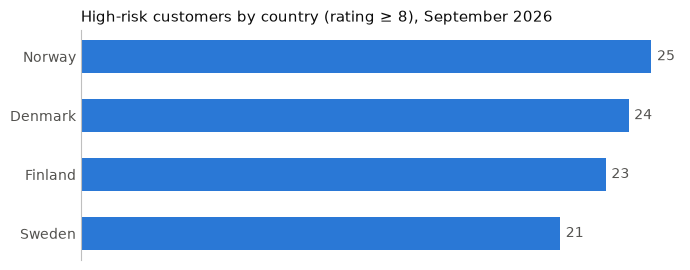

In [16]:
counts = summary.drop(index="Total")["high_risk"].sort_values()

fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(counts.index, counts.values, color="#2a78d6", height=0.55)
ax.bar_label(bars, padding=4, color="#52514e", fontsize=10)
ax.set_title(f"High-risk customers by country (rating ≥ {HIGH_RISK_THRESHOLD}), {period}",
             loc="left", fontsize=11, color="#0b0b0b")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.spines["left"].set_color("#BFBFBF")
ax.tick_params(axis="x", bottom=False, labelbottom=False)
ax.tick_params(axis="y", length=0, labelcolor="#52514e")
plt.tight_layout()
plt.show()

In [17]:
run_log = {
    "run_timestamp": datetime.now().isoformat(timespec="seconds"),
    "snapshot_date": snapshot_label,
    "data_source": DATA_SOURCE,
    "high_risk_threshold": HIGH_RISK_THRESHOLD,
    "rows_extracted": {"loan_risk": len(loans_raw), "contacts": len(contacts_raw)},
    "duplicates_removed": {"loan_risk": len(loans_raw) - len(loans),
                           "superseded_contacts": len(contacts_raw) - len(contacts)},
    "customers_reported": len(report),
    "high_risk_customers": int(high_risk_mask.sum()),
    "excel_files_written": len(files_df),
    "email_drafts": len(email_log),
    "data_quality_findings": {
        "customers_without_responsible": no_responsible["ORG_ID"].tolist(),
        "contacts_for_customers_not_in_portfolio": orphan_contacts["ORG_ID"].tolist(),
        "customers_pending_rating": report.loc[report["Risk Category"] == "Pending rating", "Org ID"].tolist(),
        "branch_mismatches": branch_mismatch["ORG_ID"].tolist(),
    },
}
(run_dir / "run_log.json").write_text(json.dumps(run_log, indent=2), encoding="utf-8")
print(json.dumps({k: v for k, v in run_log.items() if k != "data_quality_findings"}, indent=2))

{
  "run_timestamp": "2026-10-11T15:31:54",
  "snapshot_date": "2026-09-30",
  "data_source": "snowflake",
  "high_risk_threshold": 8,
  "rows_extracted": {
    "loan_risk": 812,
    "contacts": 813
  },
  "duplicates_removed": {
    "loan_risk": 12,
    "superseded_contacts": 15
  },
  "customers_reported": 800,
  "high_risk_customers": 93,
  "excel_files_written": 17,
  "email_drafts": 33
}


## Results and impact

One run of this notebook replaces the full manual routine:

- **Extracts** two source tables straight from Snowflake: no manual exports.
- **Finds and fixes** duplicates, inconsistent keys, 16 spellings of four countries, mixed phone formats and outdated contact assignments.
- **Produces** 4 country master workbooks and 13 branch workbooks with consistent formatting, reconciled so every customer appears in exactly one branch file.
- **Drafts** one targeted e-mail per relationship manager covering every high-risk customer, ready for review.
- **Logs** each run for traceability.

Done manually, this meant repetitive filtering and copy-paste across 17 files and dozens of e-mails every month, where one wrong filter sends a branch another branch's customers. The automated version runs in seconds, produces the same output every time, and makes data quality issues visible instead of hiding them.

## What I would add next

- **Scheduling:** run automatically after the monthly snapshot lands (e.g. Windows Task Scheduler, Airflow, or a Snowflake Task + Python stored procedure).
- **Push transformations into Snowflake:** move the cleaning logic into SQL views or a **dbt** model, so the notebook only handles distribution.
- **Unit tests** for the cleaning functions (`pytest`), e.g. `normalise_phone` and `standardise_country`.
- **Secure distribution:** write branch files to SharePoint/Teams folders with access per branch, instead of attaching data to e-mail.